# ДЗ-4. Full Fine-Tuning и LoRA на русскоязычном QA

## 1. Окружение и параметры

In [1]:
import gc
import hashlib
import json
import random
import time
import unicodedata
from collections import Counter
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import Dataset, concatenate_datasets, load_dataset
from IPython.display import display
from peft import LoraConfig, PeftModel, get_peft_model
from tqdm.auto import tqdm
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    DataCollatorForSeq2Seq,
    GenerationConfig,
    Trainer,
    TrainingArguments,
    set_seed,
)

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
MODEL_REVISION = "989aa7980e4cf806f80c7fef2b1adb7bc71aa306"
DATASET_NAME = "kuznetsoffandrey/sberquad"
DATASET_REVISION = "deb870ee29b280657470f2c3851e9b23899fdbc3"
SEED = 42
RUN_NAME = "main"
TRAIN_SIZE, VAL_SIZE, TEST_SIZE = 20_000, 1_000, 2_000
MAX_LENGTH = 1024
MAX_NEW_TOKENS = 128
EPOCHS = 1
MICRO_BATCH_SIZE = 1
GRAD_ACCUMULATION = 16
EVAL_BATCH_SIZE = 8
FULL_LR, LORA_LR = 2e-5, 2e-4

SYSTEM_PROMPT = (
    "Ответь на вопрос по приведённому тексту. "
    "Верни только короткий фрагмент текста с ответом, без пояснений."
)
RESULT_DIR = Path("results") / RUN_NAME
CHECKPOINT_DIR = Path("checkpoints") / RUN_NAME
RESULT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
set_seed(SEED)
torch.backends.cuda.matmul.allow_tf32 = True
pd.set_option("display.max_colwidth", 140)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, revision=MODEL_REVISION)
tokenizer.padding_side = "right"
generation_config = GenerationConfig(
    max_new_tokens=MAX_NEW_TOKENS,
    do_sample=False,
    num_beams=1,
    eos_token_id=tokenizer.eos_token_id,
    pad_token_id=tokenizer.pad_token_id,
)

/home/saumnov/study/HSE_LLM/4/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
environment = {
    "gpu": torch.cuda.get_device_name(0),
    "gpu_memory_gib": round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2),
    "cuda": torch.version.cuda,
    "versions": {name: version(name) for name in [
        "torch", "transformers", "peft", "accelerate", "datasets", "pandas", "matplotlib"
    ]},
}
display(environment)

{'gpu': 'NVIDIA A100 80GB PCIe',
 'gpu_memory_gib': 79.15,
 'cuda': '12.6',
 'versions': {'torch': '2.8.0+cu126',
  'transformers': '4.56.1',
  'peft': '0.17.1',
  'accelerate': '1.6.0',
  'datasets': '3.6.0',
  'pandas': '2.2.3',
  'matplotlib': '3.10.1'}}

## 2. Данные

Выбор пал на [SberQuAD](https://huggingface.co/datasets/kuznetsoffandrey/sberquad): вопросы по русскоязычным
текстам Википедии с человеческой разметкой. В доступных размеченных частях `train` и `validation`
45 328 и 5 036 примеров.

Объединяю эти две размеченные части и заново делю их по контекстам в пропорции 80/10/10.
Вопросы к одному контексту остаются в одной части.  Удаляю дубликаты «контекст — вопрос» и примеры без непустого ответа, встречающегося в контексте.
Из каждой части выбираю фиксированную подвыборку. 

In [3]:
raw_parts = load_dataset(
    DATASET_NAME, revision=DATASET_REVISION, split=["train", "validation"]
)
raw_data = concatenate_datasets([
    part.add_column("example_id", [f"{name}:{i}" for i in part["id"]])
    for name, part in zip(["train", "validation"], raw_parts)
])
frame = raw_data.to_pandas().drop_duplicates(subset=["context", "question"])
data = Dataset.from_pandas(frame, preserve_index=False)
data = data.filter(lambda row: any(
    answer.strip() and answer.strip() in row["context"]
    for answer in row["answers"]["text"]
))
display(pd.DataFrame([
    {"контекст": row["context"], "вопрос": row["question"], "ответы": row["answers"]["text"]}
    for row in data.shuffle(seed=SEED).select(range(3))
]))


Filter:   0%|          | 0/50361 [00:00<?, ? examples/s]


Filter:  30%|██▉       | 15000/50361 [00:00<00:00, 141219.50 examples/s]


Filter:  60%|█████▉    | 30000/50361 [00:00<00:00, 140218.82 examples/s]


Filter:  89%|████████▉ | 45000/50361 [00:00<00:00, 139525.95 examples/s]


Filter: 100%|██████████| 50361/50361 [00:00<00:00, 138914.49 examples/s]

,контекст,вопрос,ответы
0,"Переме́нная звезда́ — звезда, блеск которой изменяется со временем в результате происходящих в её районе физических процессов. Строго го...",Какое условие достаточно для отнесения звезды к разряду переменных,[чтобы блеск звезды хотя бы однажды претерпел изменение]
1,"Различают вертикальные концерны, горизонтальные концерны, и смешанные концерны (также называемые конгломератами). Под вертикальными пони...",Как еще называют смешанные концерны?,[конгломератами]
2,Языковой вопрос в Манитобе показал глубокие расхождения в культурных ценностях на территории провинции. Франко-католические манитобцы бы...,В какие годы в Манитобе было политическое движение английских протестантов против франко-католическов?,[с 1888 года по 1890 год]


In [4]:
def prepare_example(row):
    references = [a.strip() for a in row["answers"]["text"] if a.strip() and a.strip() in row["context"]]
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"Текст: {row['context']}\n\nВопрос: {row['question']}"},
    ]
    prompt_ids = tokenizer.apply_chat_template(messages, tokenize=True, add_generation_prompt=True)
    answer_ids = tokenizer(references, add_special_tokens=False)["input_ids"]
    target_ids = answer_ids[0] + [tokenizer.eos_token_id]
    context_key = " ".join(row["context"].split())
    return {
        "references": references,
        "context_group": hashlib.sha256(context_key.encode()).hexdigest(),
        "prompt_ids": prompt_ids,
        "prompt_length": len(prompt_ids),
        "max_answer_length": max(map(len, answer_ids)) + 1,
        "input_ids": prompt_ids + target_ids,
        "attention_mask": [1] * (len(prompt_ids) + len(target_ids)),
        "labels": [-100] * len(prompt_ids) + target_ids,
    }

prepared = data.map(prepare_example)
prepared = prepared.filter(lambda row: (
    row["prompt_length"] + row["max_answer_length"] <= MAX_LENGTH
    and row["max_answer_length"] <= MAX_NEW_TOKENS
))
groups = sorted(set(prepared["context_group"]))
random.Random(SEED).shuffle(groups)
train_end, val_end = int(0.8 * len(groups)), int(0.9 * len(groups))
group_split = {
    group: "train" if i < train_end else "validation" if i < val_end else "test"
    for i, group in enumerate(groups)
}
splits = {}
for name, size in [("train", TRAIN_SIZE), ("validation", VAL_SIZE), ("test", TEST_SIZE)]:
    indices = [i for i, group in enumerate(prepared["context_group"]) if group_split[group] == name]
    splits[name] = prepared.select(indices).shuffle(seed=SEED).select(range(size))

train_data, val_data, test_data = [splits[name] for name in ["train", "validation", "test"]]
train_tokens = train_data.select_columns(["input_ids", "attention_mask", "labels"])
split_ids = {name: split["example_id"] for name, split in splits.items()}
manual_ids = test_data.shuffle(seed=SEED + 1).select(range(10))["example_id"]
display(pd.DataFrame([
    {"этап": "Исходные размеченные данные", "примеров": len(raw_data)},
    {"этап": "После удаления дублей и проверки ответов", "примеров": len(data)},
    {"этап": "После ограничения длины", "примеров": len(prepared)},
] + [
    {"этап": name, "примеров": len(split)} for name, split in splits.items()
]))
display(pd.DataFrame({
    name: pd.Series(split["prompt_length"]).describe(percentiles=[0.5, 0.9, 0.95])
    for name, split in splits.items()
}).round(1))


Map:   0%|          | 0/41446 [00:00<?, ? examples/s]


Map:   0%|          | 89/41446 [00:00<00:47, 876.13 examples/s]


Map:   0%|          | 198/41446 [00:00<00:41, 991.83 examples/s]


Map:   1%|          | 302/41446 [00:00<00:40, 1009.38 examples/s]


Map:   1%|          | 410/41446 [00:00<00:39, 1033.51 examples/s]


Map:   1%|          | 517/41446 [00:00<00:39, 1045.31 examples/s]

... (434 outputs left out)


Filter:  97%|█████████▋| 40000/41446 [00:02<00:00, 18276.63 examples/s]


Filter: 100%|██████████| 41446/41446 [00:02<00:00, 17082.35 examples/s]

,этап,примеров
0,Исходные размеченные данные,50364
1,После удаления дублей и проверки ответов,41446
2,После ограничения длины,41406
3,train,20000
4,validation,1000
5,test,2000


,train,validation,test
count,20000.0,1000.0,2000.0
mean,338.2,343.2,332.2
std,87.4,88.7,83.6
min,174.0,193.0,190.0
50%,316.0,322.5,309.0
90%,455.0,469.1,447.0
95%,508.0,512.1,498.0
max,1007.0,743.0,853.0


In [5]:
run_config = {
    "model": MODEL_NAME, "model_revision": MODEL_REVISION,
    "dataset": DATASET_NAME, "dataset_revision": DATASET_REVISION,
    "seed": SEED, "train_size": TRAIN_SIZE, "val_size": VAL_SIZE, "test_size": TEST_SIZE,
    "split_fingerprint": hashlib.sha256(json.dumps(split_ids, sort_keys=True).encode()).hexdigest(),
    "system_prompt": SYSTEM_PROMPT, "max_length": MAX_LENGTH, "max_new_tokens": MAX_NEW_TOKENS,
    "epochs": EPOCHS, "micro_batch_size": MICRO_BATCH_SIZE, "gradient_accumulation": GRAD_ACCUMULATION,
    "eval_batch_size": EVAL_BATCH_SIZE, "full_lr": FULL_LR, "lora_lr": LORA_LR,
    "optimizer": "adamw_torch", "scheduler": "linear", "warmup_ratio": 0.05,
    "weight_decay": 0.01, "max_grad_norm": 1.0, "gradient_checkpointing": True,
    "weights_dtype": "float32", "mixed_precision": "bfloat16", "attention": "sdpa",
    "metric_normalization": "lower_yo_unicode_punctuation_spaces_v1",
    "environment": environment,
}
config_path = RESULT_DIR / "run_config.json"
if config_path.exists() and json.loads(config_path.read_text()) != run_config:
    raise ValueError("В этой папке уже другой протокол. Задайте новое RUN_NAME и повторите подготовку.")
config_path.write_text(json.dumps(run_config, ensure_ascii=False, indent=2))
(RESULT_DIR / "split_ids.json").write_text(json.dumps(split_ids, ensure_ascii=False))
(RESULT_DIR / "manual_ids.json").write_text(json.dumps(manual_ids, ensure_ascii=False))
test_data.select_columns(["example_id", "context", "question", "references"]).to_json(
    RESULT_DIR / "test_examples.jsonl", force_ascii=False
)


Creating json from Arrow format:   0%|          | 0/2 [00:00<?, ?ba/s]


Creating json from Arrow format: 100%|██████████| 2/2 [00:00<00:00, 32.68ba/s]

3162068

## 3. Метрики и генерация
По метрикам я решил взять следующие две:
**Exact Match (EM)** — доля ответов, совпавших с эталоном после нормализации.
**Token F1** — F1 по совпадению слов с учётом их повторений. EM оценивает строгую правильность,
F1 учитывает частично верные ответы.

In [6]:
def normalize_answer(text):
    text = text.lower().replace("ё", "е")
    text = "".join(" " if unicodedata.category(char).startswith("P") else char for char in text)
    return " ".join(text.split())


def answer_scores(prediction, references):
    prediction = normalize_answer(prediction)
    pred_words = prediction.split()
    exact_matches, f1_scores = [], []
    for reference in references:
        reference = normalize_answer(reference)
        ref_words = reference.split()
        exact_matches.append(float(prediction == reference))
        overlap = sum((Counter(pred_words) & Counter(ref_words)).values())
        denominator = len(pred_words) + len(ref_words)
        f1_scores.append(2 * overlap / denominator if denominator else 1.0)
    return {"em": 100 * max(exact_matches), "f1": 100 * max(f1_scores)}


@torch.inference_mode()
def evaluate_answers(model, dataset):
    model.eval()
    model.config.use_cache = True
    tokenizer.padding_side = "left"
    dataset = dataset.sort("prompt_length")
    rows = []
    for start in tqdm(range(0, len(dataset), EVAL_BATCH_SIZE), desc="Генерация"):
        batch = dataset[start:start + EVAL_BATCH_SIZE]
        inputs = tokenizer.pad(
            {"input_ids": batch["prompt_ids"]}, padding=True, pad_to_multiple_of=8, return_tensors="pt"
        ).to("cuda")
        with torch.autocast("cuda", dtype=torch.bfloat16):
            output = model.generate(**inputs, generation_config=generation_config, use_model_defaults=False)
        predictions = tokenizer.batch_decode(output[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)
        for example_id, prediction, references in zip(batch["example_id"], predictions, batch["references"]):
            rows.append({
                "example_id": example_id, "prediction": prediction.strip(),
                **answer_scores(prediction, references),
            })
    tokenizer.padding_side = "right"
    predictions = pd.DataFrame(rows)
    return predictions[["em", "f1"]].mean().to_dict(), predictions


def load_base_model():
    return AutoModelForCausalLM.from_pretrained(
        MODEL_NAME, revision=MODEL_REVISION, dtype=torch.float32, attn_implementation="sdpa"
    ).to("cuda")

## 4. Конфигурации экспериментов

Базовая LoRA: `r=16`, `alpha=32`, `dropout=0.05`, модули `q_proj` и `v_proj`.
В каждом из восьми дополнительных запусков меняю только один из этих параметров.
Каждая модель начинает с исходных весов Qwen.

В варианте `attention` адаптеры добавляются к `q/k/v/o_proj`, в `attention_mlp` — также к `gate/up/down_proj`.

In [7]:
lora_base = {
    "r": 16, "lora_alpha": 32, "lora_dropout": 0.05,
    "target_modules": ["q_proj", "v_proj"],
}
attention_modules = ["q_proj", "k_proj", "v_proj", "o_proj"]
lora_variants = [
    ("lora_base", {}),
    ("lora_r8", {"r": 8}),
    ("lora_r32", {"r": 32}),
    ("lora_alpha16", {"lora_alpha": 16}),
    ("lora_alpha64", {"lora_alpha": 64}),
    ("lora_dropout0", {"lora_dropout": 0.0}),
    ("lora_dropout01", {"lora_dropout": 0.1}),
    ("lora_attention", {"target_modules": attention_modules}),
    ("lora_attention_mlp", {"target_modules": attention_modules + ["gate_proj", "up_proj", "down_proj"]}),
]
experiments = [{"name": "base", "method": "base"}, {"name": "full_ft", "method": "full_ft"}] + [
    {"name": name, "method": "lora", **lora_base, **changes}
    for name, changes in lora_variants
]
(RESULT_DIR / "experiments.json").write_text(json.dumps(experiments, ensure_ascii=False, indent=2))
display(pd.DataFrame(experiments))

,name,method,r,lora_alpha,lora_dropout,target_modules
0,base,base,NaN,NaN,NaN,NaN
1,full_ft,full_ft,NaN,NaN,NaN,NaN
2,lora_base,lora,16.0,32.0,0.05,"[q_proj, v_proj]"
3,lora_r8,lora,8.0,32.0,0.05,"[q_proj, v_proj]"
4,lora_r32,lora,32.0,32.0,0.05,"[q_proj, v_proj]"
5,lora_alpha16,lora,16.0,16.0,0.05,"[q_proj, v_proj]"
6,lora_alpha64,lora,16.0,64.0,0.05,"[q_proj, v_proj]"
7,lora_dropout0,lora,16.0,32.0,0.00,"[q_proj, v_proj]"
8,lora_dropout01,lora,16.0,32.0,0.10,"[q_proj, v_proj]"
9,lora_attention,lora,16.0,32.0,0.05,"[q_proj, k_proj, v_proj, o_proj]"


## 5. Обучение и оценка на validation

Обучения длились одну эпоху на 20 000 примерах, 1 250 шагов оптимизатора и эффективный batch size 16. Learning rate составил `2e-5` для Full FT и `2e-4` для всех LoRA. Использовались AdamW, линейный scheduler, warmup 5%, gradient checkpointing и BF16 autocast при хранении весов в FP32.

In [8]:
def run_experiment(config, pilot=False):
    name = "pilot_full_ft" if pilot else config["name"]
    output_dir = RESULT_DIR / name
    output_dir.mkdir(exist_ok=True)
    metrics_path = output_dir / "validation_metrics.json"
    if metrics_path.exists() and not pilot:
        saved = json.loads(metrics_path.read_text())
        if saved["config"] != config:
            raise ValueError(f"Изменена конфигурация {name}. Задайте новое RUN_NAME.")
        print(f"{name}: использую сохранённый результат")
        return saved

    set_seed(SEED)
    gc.collect()
    torch.cuda.empty_cache()
    tokenizer.padding_side = "right"
    model = load_base_model()
    if config["method"] == "lora":
        model = get_peft_model(model, LoraConfig(
            task_type="CAUSAL_LM", bias="none", use_rslora=False,
            **{key: config[key] for key in lora_base},
        ))
    elif config["method"] == "base":
        model.requires_grad_(False)

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    stats = {
        "name": name, "config": config, "trainable_params": trainable,
        "trainable_percent": 100 * trainable / total, "train_seconds": 0.0,
        "peak_allocated_gib": None, "peak_reserved_gib": None,
    }
    if config["method"] != "base":
        model.config.use_cache = False
        args = TrainingArguments(
            output_dir=str(CHECKPOINT_DIR / name),
            num_train_epochs=EPOCHS, max_steps=10 if pilot else -1,
            per_device_train_batch_size=MICRO_BATCH_SIZE,
            gradient_accumulation_steps=GRAD_ACCUMULATION,
            learning_rate=FULL_LR if config["method"] == "full_ft" else LORA_LR,
            optim="adamw_torch", lr_scheduler_type="linear", warmup_ratio=0.05,
            weight_decay=0.01, max_grad_norm=1.0,
            bf16=True, tf32=True, gradient_checkpointing=True,
            gradient_checkpointing_kwargs={"use_reentrant": False},
            logging_steps=1 if pilot else 25,
            eval_strategy="no", save_strategy="no", report_to="none",
            seed=SEED, data_seed=SEED, dataloader_num_workers=0,
            skip_memory_metrics=True, label_names=["labels"],
        )
        trainer = Trainer(
            model=model, args=args, train_dataset=train_tokens,
            data_collator=DataCollatorForSeq2Seq(tokenizer, pad_to_multiple_of=8, label_pad_token_id=-100),
            processing_class=tokenizer,
        )
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
        started = time.perf_counter()
        trainer.train()
        torch.cuda.synchronize()
        stats.update({
            "train_seconds": time.perf_counter() - started,
            "peak_allocated_gib": torch.cuda.max_memory_allocated() / 2**30,
            "peak_reserved_gib": torch.cuda.max_memory_reserved() / 2**30,
            "steps": trainer.state.global_step,
        })
        if not pilot:
            trainer.save_model(str(CHECKPOINT_DIR / name))
            (output_dir / "training_log.json").write_text(json.dumps(trainer.state.log_history, indent=2))
        del trainer
        gc.collect()
        torch.cuda.empty_cache()
        model.gradient_checkpointing_disable()

    if not pilot:
        scores, predictions = evaluate_answers(model, val_data)
        stats.update({f"val_{key}": value for key, value in scores.items()})
        predictions.to_json(output_dir / "validation_predictions.jsonl", orient="records", lines=True, force_ascii=False)
        metrics_path.write_text(json.dumps(stats, ensure_ascii=False, indent=2))
    del model
    gc.collect()
    torch.cuda.empty_cache()
    return stats

Основное сравнение: исходная модель, Full FT и базовая LoRA.

In [9]:
for experiment in experiments[:3]:
    result = run_experiment(experiment)
    display(pd.DataFrame([{key: value for key, value in result.items() if key != "config"}]))

base: использую сохранённый результат


,name,trainable_params,trainable_percent,train_seconds,peak_allocated_gib,peak_reserved_gib,val_em,val_f1
0,base,0,0.0,0.0,None,None,29.0,60.313252


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Step,Training Loss
25,0.363600
50,0.271700
75,0.315200
100,0.271600
125,0.298000
150,0.303000
175,0.269400
200,0.290000
225,0.225900
250,0.291800


/home/saumnov/study/HSE_LLM/4/.venv/lib/python3.11/site-packages/pyarrow/compute.py:231: FutureWarning: Specifying null_placement in SortOptions is deprecated as of 25.0.0. Specify null_placement per sort_key instead.
  return options_class(*args, **kwargs)



Генерация:   0%|          | 0/125 [00:00<?, ?it/s]

... (255 outputs left out)


Генерация:  99%|█████████▉| 124/125 [02:08<00:01,  1.17s/it]


Генерация: 100%|██████████| 125/125 [02:09<00:00,  1.10s/it]


Генерация: 100%|██████████| 125/125 [02:09<00:00,  1.04s/it]

,name,trainable_params,trainable_percent,train_seconds,peak_allocated_gib,peak_reserved_gib,steps,val_em,val_f1
0,lora_base,2179072,0.140959,4446.098588,8.147194,17.082031,1250,62.0,82.262588


Дополнительные конфигурации LoRA. Все восемь запусков используют те же данные и один seed.

In [10]:
for experiment in experiments[3:]:
    result = run_experiment(experiment)
    display(pd.DataFrame([{key: value for key, value in result.items() if key != "config"}]))

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Step,Training Loss
25,0.476000
50,0.316700
75,0.264600
100,0.228700
125,0.238900
150,0.250400
175,0.233400
200,0.230500
225,0.189800
250,0.231400


/home/saumnov/study/HSE_LLM/4/.venv/lib/python3.11/site-packages/pyarrow/compute.py:231: FutureWarning: Specifying null_placement in SortOptions is deprecated as of 25.0.0. Specify null_placement per sort_key instead.
  return options_class(*args, **kwargs)



Генерация:   0%|          | 0/125 [00:00<?, ?it/s]


Генерация:   1%|          | 1/125 [00:00<01:01,  2.00it/s]


Генерация:   2%|▏         | 2/125 [00:01<01:21,  1.50it/s]

... (1,040 outputs left out)


Генерация:  99%|█████████▉| 124/125 [03:09<00:01,  1.82s/it]


Генерация: 100%|██████████| 125/125 [03:10<00:00,  1.68s/it]


Генерация: 100%|██████████| 125/125 [03:10<00:00,  1.52s/it]

,name,trainable_params,trainable_percent,train_seconds,peak_allocated_gib,peak_reserved_gib,steps,val_em,val_f1
0,lora_attention_mlp,18464768,1.181988,7361.233251,8.38987,17.365234,1250,63.8,83.674381


## 6. Финальная оценка на test

Все 11 вариантов оценены на одинаковых 2 000 тестовых примерах. Конфигурации были зафиксированы до просмотра test, а лучшая LoRA выбрана по validation F1: `lora_attention_mlp` с 83,67%. Её test EM/F1 составили 63,60% / 84,46%.

In [11]:
for experiment in experiments:
    name = experiment["name"]
    output_dir = RESULT_DIR / name
    test_metrics_path = output_dir / "test_metrics.json"
    saved = json.loads((output_dir / "validation_metrics.json").read_text())
    if saved["config"] != experiment:
        raise ValueError(f"Конфигурация {name} отличается от обученной модели.")
    if test_metrics_path.exists():
        print(f"{name}: test уже рассчитан")
        continue
    gc.collect()
    torch.cuda.empty_cache()
    if experiment["method"] == "full_ft":
        model = AutoModelForCausalLM.from_pretrained(
            CHECKPOINT_DIR / name, dtype=torch.float32, attn_implementation="sdpa"
        ).to("cuda")
    else:
        model = load_base_model()
        if experiment["method"] == "lora":
            model = PeftModel.from_pretrained(model, CHECKPOINT_DIR / name)
    scores, predictions = evaluate_answers(model, test_data)
    predictions.to_json(output_dir / "test_predictions.jsonl", orient="records", lines=True, force_ascii=False)
    test_metrics_path.write_text(json.dumps({f"test_{key}": value for key, value in scores.items()}, indent=2))
    del model
    gc.collect()
    torch.cuda.empty_cache()

/home/saumnov/study/HSE_LLM/4/.venv/lib/python3.11/site-packages/pyarrow/compute.py:231: FutureWarning: Specifying null_placement in SortOptions is deprecated as of 25.0.0. Specify null_placement per sort_key instead.
  return options_class(*args, **kwargs)



Генерация:   0%|          | 0/250 [00:00<?, ?it/s]


Генерация:   0%|          | 1/250 [00:00<04:07,  1.00it/s]


Генерация:   1%|          | 2/250 [00:02<05:43,  1.38s/it]


Генерация:   1%|          | 3/250 [00:04<06:38,  1.62s/it]


Генерация:   2%|▏         | 4/250 [00:05<05:29,  1.34s/it]

... (2,775 outputs left out)


Генерация:  99%|█████████▉| 248/250 [06:11<00:02,  1.41s/it]


Генерация: 100%|█████████▉| 249/250 [06:12<00:01,  1.49s/it]


Генерация: 100%|██████████| 250/250 [06:14<00:00,  1.63s/it]


Генерация: 100%|██████████| 250/250 [06:14<00:00,  1.50s/it]

## 7. Итоговые таблицы

Full FT повысил test EM/F1 с 29,00% / 60,17% до 61,15% / 82,23%, а базовая LoRA — до 62,35% / 83,63%. Таким образом, оба способа улучшили автоматические метрики, причём базовая LoRA превысила Full FT на 1,20 п.п. EM и 1,40 п.п. F1.

Время указано в минутах, память — в GiB. В выводе общей таблицы learning rate округлён до нуля; фактические значения — `2e-5` для Full FT и `2e-4` для LoRA.

In [12]:
rows = []
for experiment in experiments:
    name = experiment["name"]
    output_dir = RESULT_DIR / name
    stats = json.loads((output_dir / "validation_metrics.json").read_text())
    trained_config = stats.pop("config")
    scores = json.loads((output_dir / "test_metrics.json").read_text())
    rows.append({
        **trained_config, **stats, **scores,
        "target_modules": ", ".join(trained_config.get("target_modules", [])),
        "learning_rate": FULL_LR if name == "full_ft" else LORA_LR if experiment["method"] == "lora" else None,
        "epochs": 0 if name == "base" else EPOCHS,
    })
results = pd.DataFrame(rows).set_index("name")
results["train_minutes"] = results["train_seconds"] / 60
results["trainable_millions"] = results["trainable_params"] / 1e6
results.to_csv(RESULT_DIR / "metrics.csv")
display(results[[
    "r", "lora_alpha", "lora_dropout", "target_modules", "learning_rate", "epochs",
    "val_em", "val_f1", "test_em", "test_f1", "trainable_millions", "trainable_percent",
    "train_minutes", "peak_allocated_gib", "peak_reserved_gib",
]].round(3))

best_lora = results.loc[results["method"] == "lora", "val_f1"].idxmax()
print("Лучшая LoRA по validation F1:", best_lora)
display(results.loc[list(dict.fromkeys(["base", "full_ft", "lora_base", best_lora])), [
    "test_em", "test_f1", "trainable_millions", "train_minutes", "peak_allocated_gib"
]].round(3))

,r,lora_alpha,lora_dropout,target_modules,learning_rate,epochs,val_em,val_f1,test_em,test_f1,trainable_millions,trainable_percent,train_minutes,peak_allocated_gib,peak_reserved_gib
name,,,,,,,,,,,,,,,
base,NaN,NaN,NaN,,NaN,0,29.0,60.313,29.00,60.170,0.000,0.000,0.000,NaN,NaN
full_ft,NaN,NaN,NaN,,0.0,1,61.0,81.702,61.15,82.229,1543.714,100.000,68.290,28.836,31.379
lora_base,16.0,32.0,0.05,"q_proj, v_proj",0.0,1,62.0,82.263,62.35,83.628,2.179,0.141,74.102,8.147,17.082
lora_r8,8.0,32.0,0.05,"q_proj, v_proj",0.0,1,61.4,82.183,61.95,83.378,1.090,0.071,74.051,8.131,17.066
lora_r32,32.0,32.0,0.05,"q_proj, v_proj",0.0,1,61.1,81.800,62.05,83.844,4.358,0.282,72.830,8.180,17.119
lora_alpha16,16.0,16.0,0.05,"q_proj, v_proj",0.0,1,61.5,81.885,61.05,82.896,2.179,0.141,74.316,8.147,17.082
lora_alpha64,16.0,64.0,0.05,"q_proj, v_proj",0.0,1,62.9,82.765,62.30,83.596,2.179,0.141,74.011,8.147,17.082
lora_dropout0,16.0,32.0,0.00,"q_proj, v_proj",0.0,1,62.4,82.636,62.40,83.846,2.179,0.141,71.649,8.147,17.082
lora_dropout01,16.0,32.0,0.10,"q_proj, v_proj",0.0,1,61.5,82.313,62.40,83.849,2.179,0.141,73.168,8.147,17.082


Лучшая LoRA по validation F1: lora_attention_mlp


,test_em,test_f1,trainable_millions,train_minutes,peak_allocated_gib
name,,,,,
base,29.00,60.170,0.000,0.000,NaN
full_ft,61.15,82.229,1543.714,68.290,28.836
lora_base,62.35,83.628,2.179,74.102,8.147
lora_attention_mlp,63.60,84.464,18.465,122.687,8.390


,parameter,experiment,delta_em_pp,delta_f1_pp
0,r,lora_r8,-0.40,-0.250
1,r,lora_base,0.00,0.000
2,r,lora_r32,-0.30,0.217
3,alpha,lora_alpha16,-1.30,-0.732
4,alpha,lora_base,0.00,0.000
5,alpha,lora_alpha64,-0.05,-0.031
6,dropout,lora_dropout0,0.05,0.218
7,dropout,lora_base,0.00,0.000
8,dropout,lora_dropout01,0.05,0.222
9,target_modules,lora_base,0.00,0.000


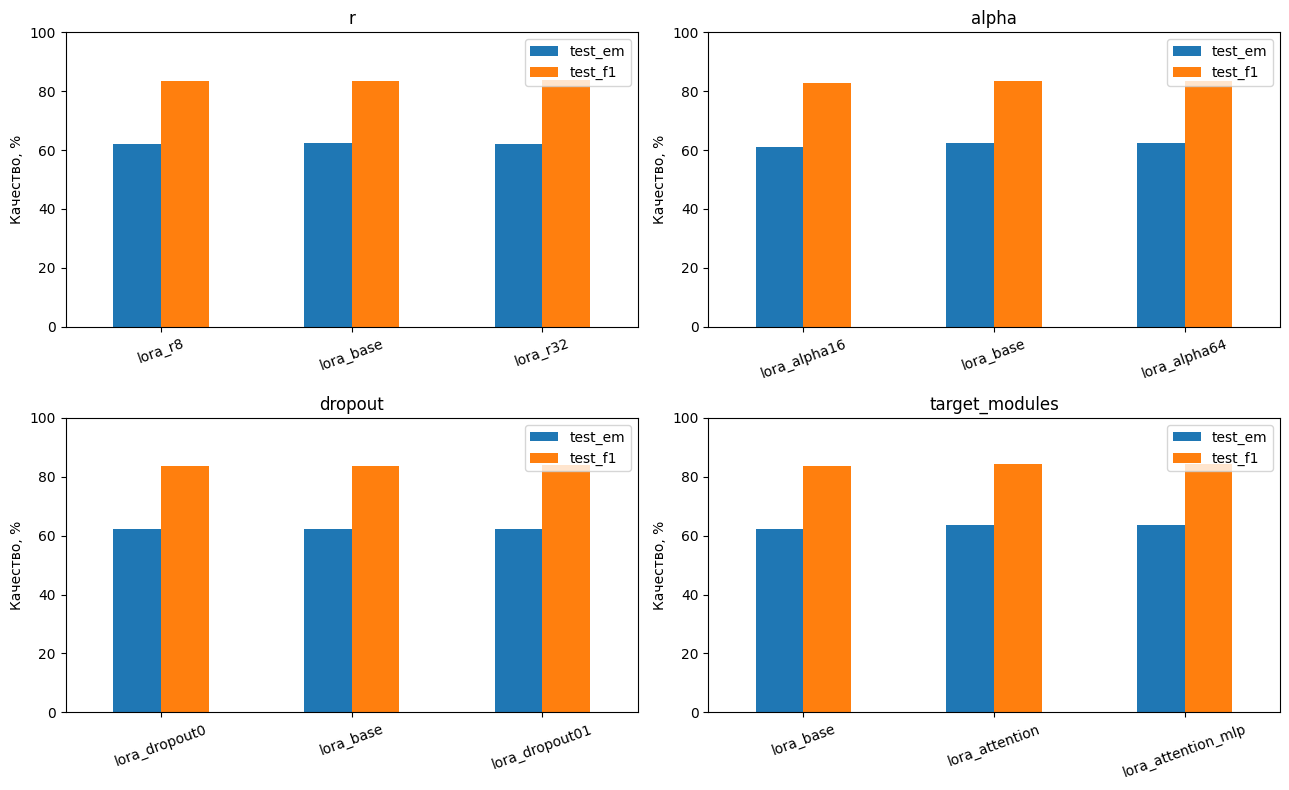

In [13]:
parameter_groups = {
    "r": ["lora_r8", "lora_base", "lora_r32"],
    "alpha": ["lora_alpha16", "lora_base", "lora_alpha64"],
    "dropout": ["lora_dropout0", "lora_base", "lora_dropout01"],
    "target_modules": ["lora_base", "lora_attention", "lora_attention_mlp"],
}
effects = []
for parameter, names in parameter_groups.items():
    for name in names:
        effects.append({
            "parameter": parameter, "experiment": name,
            "delta_em_pp": results.loc[name, "test_em"] - results.loc["lora_base", "test_em"],
            "delta_f1_pp": results.loc[name, "test_f1"] - results.loc["lora_base", "test_f1"],
        })
effects = pd.DataFrame(effects)
effects.to_csv(RESULT_DIR / "lora_effects.csv", index=False)
display(effects.round(3))

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (parameter, names) in zip(axes.flat, parameter_groups.items()):
    results.loc[names, ["test_em", "test_f1"]].plot.bar(ax=ax, rot=20)
    ax.set_title(parameter)
    ax.set_xlabel("")
    ax.set_ylabel("Качество, %")
    ax.set_ylim(0, 100)
fig.tight_layout()
fig.savefig(RESULT_DIR / "lora_parameters.png", dpi=150, bbox_inches="tight")
plt.show()

- **`r`.** При рангах 8, 16 и 32 test F1 составил 83,38%, 83,63% и 83,84%, а число обучаемых параметров — 1,09, 2,18 и 4,36 млн. Рост ранга дал небольшой прирост F1, но EM был выше при `r=16`: 62,35% против 62,05% у `r=32`. На validation ранг 32 также уступил 16. Однозначного выигрыша от увеличения ранга нет; при фиксированном `alpha=32` одновременно менялся масштаб `alpha/r`.
- **`alpha`.** Увеличение с 16 до 32 повысило test EM на 1,30 п.п., а F1 — на 0,73 п.п. При `alpha=64` validation F1 вырос до 82,77%, но test F1 остался практически на уровне базовой LoRA: 83,60% против 83,63%. Дальнейшего улучшения на test не получилось.
- **`dropout`.** При значениях 0, 0,05 и 0,1 test F1 составил 83,85%, 83,63% и 83,85%. У вариантов 0 и 0,1 одинаковый EM — 62,40%, а разница F1 меньше 0,01 п.п. На validation лучшим из трёх был вариант без dropout. В этой серии явной пользы от усиления регуляризации не видно.
- **`target_modules`.** Добавление адаптеров ко всем проекциям attention повысило test EM/F1 до 63,60% / 84,51%: это +1,25 и +0,88 п.п. к базовой LoRA. Время выросло с 74,10 до 92,27 минуты, число обучаемых параметров — с 2,18 до 4,36 млн. Добавление MLP дало лучший validation F1 (83,67%), но test F1 оказался почти таким же — 84,46%, при 18,46 млн параметров и 122,69 минуты обучения. На test дополнительные затраты на MLP не дали прироста качества.

Наиболее заметный выигрыш дала смена `target_modules`. Различия между рангами и значениями dropout небольшие.

## 8. Ручная оценка

Я сравнил ответы трёх моделей на десяти заранее выбранных тестовых примерах. Шкала: **2** — правильный и достаточный ответ без неподтверждённых утверждений; **1** — частично правильный ответ или существенная неточность; **0** — ответ не раскрывает вопрос или неверен. Различия в предлогах и повторение формулировки вопроса сами по себе не снижали оценку.

In [14]:
manual_path = RESULT_DIR / "manual_review.csv"
if not manual_path.exists():
    examples = pd.read_json(RESULT_DIR / "test_examples.jsonl", lines=True).set_index("example_id")
    manual = examples.loc[manual_ids, ["context", "question", "references"]].copy()
    for name in ["base", "full_ft", "lora_base"]:
        predictions = pd.read_json(RESULT_DIR / name / "test_predictions.jsonl", lines=True).set_index("example_id")
        manual[name] = predictions.loc[manual_ids, "prediction"]
        manual[f"{name}_score"] = pd.NA
    manual["comment"] = ""
    manual.to_csv(manual_path)

manual = pd.read_csv(manual_path, keep_default_na=False)
with pd.option_context("display.max_colwidth", None):
    display(manual[["example_id", "question", "references", "base", "full_ft", "lora_base"]])

,example_id,question,references,base,full_ft,lora_base
0,train:77798,В каком году планируется возводить мост?,['в 2015 году'],2015 году,в 2015 году,в 2015 году
1,train:5003,Из чего складывается эффективность производства?,['из эффективности всех действующих предприятий'],Эффективность производства складывается из эффективности всех действующих предприятий.,из эффективности всех действующих предприятий,из эффективности всех действующих предприятий
2,train:41065,В виде чего космический аппарат расходует тепло?,['излучения'],В виде излучения.,в виде излучения,в виде излучения
3,train:64111,Какая опера положила начало Венской Придворной опере?,['Золотое яблоко'],Золотое яблоко,Золотое яблоко,Золотое яблоко
4,train:37082,У кого был арендован Россией комплекс Байконур ?,['у Казахстана'],Россией был арендован комплекс Байконур у Казахстана.,у Казахстана,у Казахстана
5,train:81424,В каком году Косово заявило о своей независимости от Сербии?,['2008'],2008,в июне 2008 года,в июне 2008 года
6,train:82897,Когда на управление эффективностью деятельности очень сильно повлияло развитие концепции Сбалансированной системы показателей?,['с 1992 г.'],1992 г.,Начиная с 1992 г.,с 1992 г.
7,train:79998,К какому типу базового порядка слов относится финский язык?,['к языкам типа SVO (Subject-Verb-Object)'],финский язык относится к типу базового порядка слов SVO (Subject-Verb-Object).,типу SVO (Subject-Verb-Object),к языкам типа SVO
8,train:55605,"Согласно чьей концепции об общем адаптационном синдроме, болезнь представляет собой напряжение ( стресс ), возникающее в организме при воздействии на него чрезвычайного раздражителя?",['Г. Селье'],Г. Селье,Г. Селье,Г. Селье
9,validation:16252,Как произносится в русском языке к (кириллица)?,['как глухой взрывной согласный [к] или [к ]'],[к] или [к],как глухой взрывной согласный,к


По ручной шкале исходная модель и Full FT получили в среднем по 1,9 из 2, базовая LoRA — 1,7. Исходная модель верно ответила по смыслу на девять вопросов, но неполно описала произношение буквы «к». Full FT допустил одну неточность с месяцем, а LoRA дополнительно не раскрыла вопрос о произношении. На этих десяти примерах улучшение автоматических метрик не сопровождалось ростом средней ручной оценки.

In [15]:
manual = pd.read_csv(manual_path, keep_default_na=False)
display(manual[["example_id", "base_score", "full_ft_score", "lora_base_score", "comment"]])
manual_scores = manual[["base_score", "full_ft_score", "lora_base_score"]].apply(pd.to_numeric, errors="coerce")
display(pd.DataFrame({
    "оценено примеров": manual_scores.count(),
    "средняя оценка": manual_scores.mean(),
}))

,example_id,base_score,full_ft_score,lora_base_score,comment
0,train:77798,2,2,2,Все верно указали 2015 год. Отсутствие предлога у исходной модели не меняет смысл.
1,train:5003,2,2,2,Все верно назвали эффективность действующих предприятий. Исходная модель повторяет вопрос в полном предложении; дообученные модели дают ...
2,train:41065,2,2,2,"Все правильно указали излучение. Слова «в виде» не меняют смысл, хотя выходят за границы эталона."
3,train:64111,2,2,2,Все правильно назвали оперу «Золотое яблоко».
4,train:37082,2,2,2,Все правильно назвали Казахстан. Полное предложение исходной модели не содержит новых неподтверждённых фактов.
5,train:81424,2,1,1,"Исходная модель верно указала год. Full FT и LoRA добавили июнь: в контексте это месяц основания банка, а месяц провозглашения независим..."
6,train:82897,2,2,2,"Все верно указали 1992 год. Различия «1992 г.», «начиная с» и «с» не мешают ответить на вопрос."
7,train:79998,2,2,2,Все верно указали порядок SVO. Отсутствие расшифровки аббревиатуры у LoRA не делает ответ неполным для этого вопроса.
8,train:55605,2,2,2,Все правильно указали Г. Селье.
9,validation:16252,1,2,0,Исходная модель дала только транскрипцию без характеристики звука. Full FT верно назвал глухой взрывной согласный. LoRA повторила букву ...


,оценено примеров,средняя оценка
base_score,10,1.9
full_ft_score,10,1.9
lora_base_score,10,1.7


- В `train:5003` и `train:37082` исходная модель дала правильные ответы полными предложениями. Full FT и LoRA выделили короткие фрагменты, совпавшие с эталонами. Это улучшение формата ответа, а не исправление фактической ошибки. В `train:41065` все три ответа «в виде излучения» верны по смыслу, хотя эталон содержит только «излучения» и EM равен нулю.
- В `train:81424` исходная модель правильно ответила «2008». Обе дообученные модели добавили «в июне», хотя в контексте июнь относится к основанию банка, а для независимости указан только год. За верный год с неподтверждённым уточнением я поставил им по 1 баллу.
- В `validation:16252` Full FT верно назвал глухой взрывной согласный. Исходная модель дала только транскрипцию без характеристики звука, а LoRA ответила одной буквой «к», не объяснив произношение. Оценки — 1, 2 и 0 соответственно.

Дообучение чаще делает ответ ближе к размеченному фрагменту, но не гарантирует улучшения каждого ответа. На этой небольшой выборке встречаются и полезное сокращение, и неподтверждённое уточнение, и потеря нужной информации.

## 9. Финальный анализ

Full FT прибавил к исходной модели 32,15 п.п. test EM и 22,06 п.п. F1, базовая LoRA — 33,35 и 23,46 п.п. При этом ручной разбор показал, что часть выигрыша связана с более точным выделением границ ответа, а отдельные ответы после обучения стали хуже.

Базовая LoRA обучала 2,18 млн параметров против 1 543,71 млн у Full FT — примерно в 708 раз меньше. Пик памяти тензоров снизился с 28,84 до 8,15 GiB, то есть в 3,54 раза; зарезервированная память — с 31,38 до 17,08 GiB. Ускорения в этом эксперименте не было: LoRA обучалась 74,10 минуты, Full FT — 68,29 минуты. Full FT оказался самым быстрым из обученных вариантов.

По validation выбрана `lora_attention_mlp`: test EM/F1 — 63,60% / 84,46%. Вариант только со всеми проекциями attention получил почти тот же test F1 — 84,51%, затратив 92,27 минуты вместо 122,69. Разница в 0,05 п.п. не даёт основания считать его устойчиво лучше выбранной по validation модели.

Для этой задачи я предпочитаю LoRA. Базовая конфигурация дала более высокие автоматические метрики, чем Full FT, при существенно меньшей памяти и умеренном увеличении времени. Она выглядит разумным выбором по соотношению качества и затрат; расширение на attention и MLP повышает validation F1, но заметно увеличивает время обучения.